In [25]:
from google.colab import drive
drive.mount('/content/drive')

import pandas as pd
df = pd.read_csv("/content/drive/MyDrive/HomeCredit/features.csv")
print(df.shape)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
(307507, 106)


In [26]:
y = df['TARGET']
ids = df['SK_ID_CURR']
X = df.drop(columns=['TARGET', 'SK_ID_CURR'])

for c in X.select_dtypes(include='object').columns:
    X[c] = X[c].astype('category')
print(X.shape)

(307507, 104)


In [27]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42)
print(X_train.shape, X_test.shape)

(246005, 104) (61502, 104)


In [28]:
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.metrics import roc_auc_score

Xn_train = X_train.select_dtypes(include='number').fillna(0)
Xn_test = X_test[Xn_train.columns].fillna(0)

lr = make_pipeline(StandardScaler(), LogisticRegression(max_iter=500, class_weight='balanced'))
lr.fit(Xn_train, y_train)
print("Logistic Regression AUC:", round(roc_auc_score(y_test, lr.predict_proba(Xn_test)[:,1]), 4))

Logistic Regression AUC: 0.7546


In [29]:
# import lightgbm as lgb

# model = lgb.LGBMClassifier(
#     n_estimators=1000, learning_rate=0.05, num_leaves=31,
#     colsample_bytree=0.7, subsample=0.8, subsample_freq=1,
#     scale_pos_weight=(y_train==0).sum()/(y_train==1).sum(),
#     random_state=42, n_jobs=-1, verbose=-1)

# model.fit(X_train, y_train,
#           eval_set=[(X_test, y_test)], eval_metric='auc',
#           callbacks=[lgb.early_stopping(50), lgb.log_evaluation(100)])

# pred = model.predict_proba(X_test)[:,1]
# print("LightGBM AUC:", round(roc_auc_score(y_test, pred), 4))



import lightgbm as lgb
from sklearn.metrics import roc_auc_score

model = lgb.LGBMClassifier(
    n_estimators=2000, learning_rate=0.03, num_leaves=31,
    min_child_samples=50, colsample_bytree=0.7,
    subsample=0.8, subsample_freq=1,
    reg_alpha=0.1, reg_lambda=0.1,
    random_state=42, n_jobs=-1)          # scale_pos_weight hata diya

model.fit(X_train, y_train,
          eval_set=[(X_test, y_test)], eval_metric='auc',
          callbacks=[lgb.early_stopping(100), lgb.log_evaluation(100)])

print("Best iteration:", model.best_iteration_)
pred = model.predict_proba(X_test)[:, 1]
print("LightGBM AUC:", round(roc_auc_score(y_test, pred), 4))

Training until validation scores don't improve for 100 rounds
[100]	valid_0's auc: 0.761425	valid_0's binary_logloss: 0.246393
[200]	valid_0's auc: 0.771921	valid_0's binary_logloss: 0.242097
[300]	valid_0's auc: 0.77522	valid_0's binary_logloss: 0.240817
[400]	valid_0's auc: 0.776697	valid_0's binary_logloss: 0.240297
[500]	valid_0's auc: 0.777393	valid_0's binary_logloss: 0.240001
[600]	valid_0's auc: 0.778005	valid_0's binary_logloss: 0.239745
[700]	valid_0's auc: 0.778562	valid_0's binary_logloss: 0.239551
[800]	valid_0's auc: 0.778821	valid_0's binary_logloss: 0.239448
[900]	valid_0's auc: 0.779208	valid_0's binary_logloss: 0.239324
[1000]	valid_0's auc: 0.779232	valid_0's binary_logloss: 0.2393
Early stopping, best iteration is:
[959]	valid_0's auc: 0.779372	valid_0's binary_logloss: 0.239278
Best iteration: 959
LightGBM AUC: 0.7794


In [30]:
from sklearn.metrics import roc_curve
auc = roc_auc_score(y_test, pred)
fpr, tpr, _ = roc_curve(y_test, pred)
print("AUC :", round(auc,4))
print("Gini:", round(2*auc-1,4))
print("KS  :", round((tpr-fpr).max(),4))

AUC : 0.7794
Gini: 0.5587
KS  : 0.4196


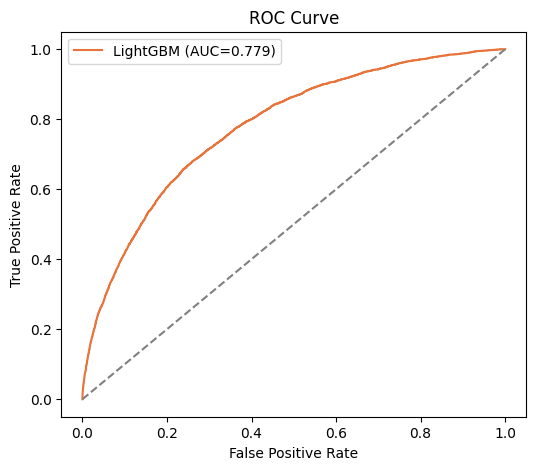

In [31]:
import matplotlib.pyplot as plt
plt.figure(figsize=(6,5))
plt.plot(fpr, tpr, color='#E8743B', label=f'LightGBM (AUC={auc:.3f})')
plt.plot([0,1],[0,1],'--', color='grey')
plt.xlabel("False Positive Rate"); plt.ylabel("True Positive Rate")
plt.title("ROC Curve"); plt.legend()
plt.savefig("roc_curve.png", dpi=150, bbox_inches='tight')
plt.show()

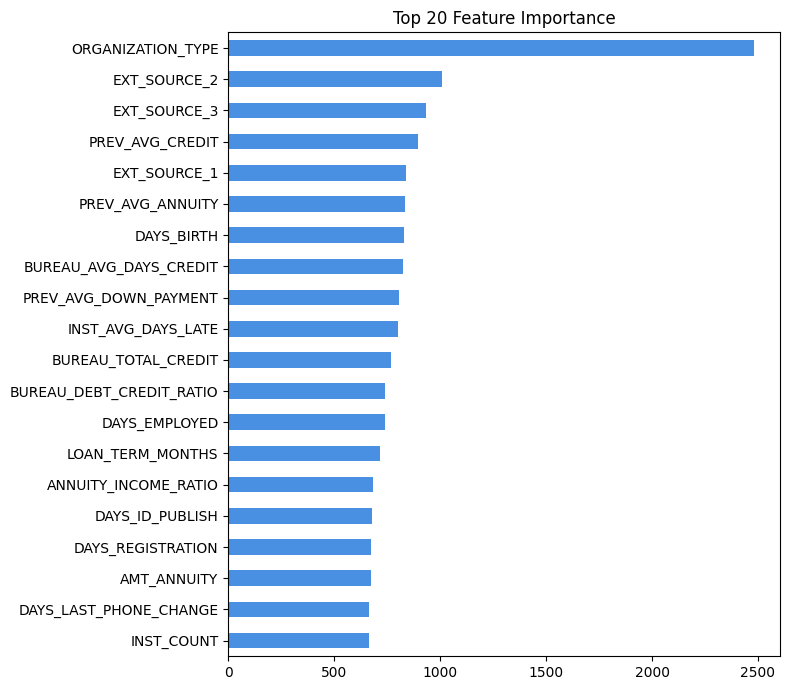

In [32]:
imp = pd.Series(model.feature_importances_, index=X.columns).sort_values().tail(20)
plt.figure(figsize=(8,7))
imp.plot(kind='barh', color='#4A90E2')
plt.title("Top 20 Feature Importance")
plt.tight_layout()
plt.savefig("feature_importance.png", dpi=150, bbox_inches='tight')
plt.show()

/usr/local/lib/python3.13/dist-packages/shap/explainers/_tree.py:578: UserWarning: LightGBM binary classifier with TreeExplainer shap values output has changed to a list of ndarray
  warnings.warn(


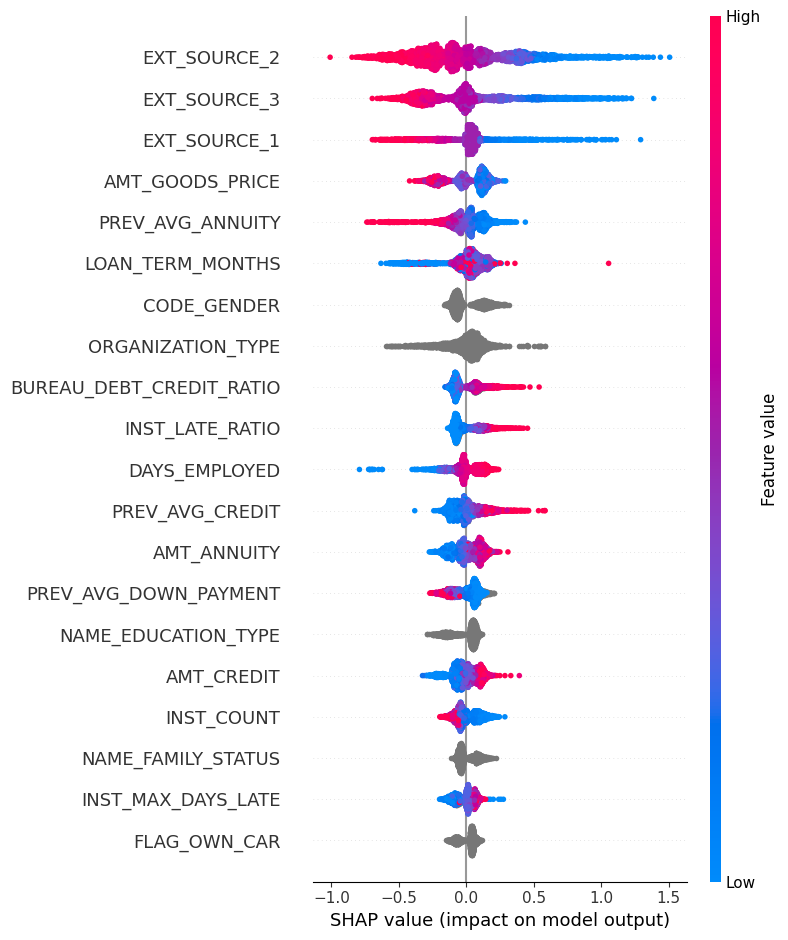

In [33]:
!pip install -q shap
import shap
sample = X_test.sample(3000, random_state=42)
explainer = shap.TreeExplainer(model)
sv = explainer.shap_values(sample)
sv = sv[1] if isinstance(sv, list) else sv
shap.summary_plot(sv, sample, show=False)
plt.savefig("shap_summary.png", dpi=150, bbox_inches='tight')
plt.show()

In [34]:
# df['risk_score'] = model.predict_proba(X)[:,1]
# df['Risk_Grade'] = pd.qcut(df['risk_score'].rank(method='first'), 7,
#                            labels=list("ABCDEFG"))

# print(df.groupby('Risk_Grade', observed=True)['TARGET'].agg(['count','mean']))



import numpy as np
import pandas as pd
from sklearn.metrics import roc_auc_score
from sklearn.model_selection import StratifiedKFold
import lightgbm as lgb

oof = np.zeros(len(X))
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

for fold, (tr, va) in enumerate(skf.split(X, y)):
    m = lgb.LGBMClassifier(
        n_estimators=model.best_iteration_, learning_rate=0.03, num_leaves=31,
        min_child_samples=50, colsample_bytree=0.7, subsample=0.8, subsample_freq=1,
        reg_alpha=0.1, reg_lambda=0.1, random_state=42, n_jobs=-1, verbose=-1)
    m.fit(X.iloc[tr], y.iloc[tr])
    oof[va] = m.predict_proba(X.iloc[va])[:, 1]
    print(f"Fold {fold+1} AUC:", round(roc_auc_score(y.iloc[va], oof[va]), 4))

print("OOF AUC (overall):", round(roc_auc_score(y, oof), 4))

df['risk_score'] = oof
df['Risk_Grade'] = pd.qcut(df['risk_score'].rank(method='first'), 7, labels=list("ABCDEFG"))
print(df.groupby('Risk_Grade', observed=True)['TARGET'].agg(['count','mean']))

Fold 1 AUC: 0.7762
Fold 2 AUC: 0.7825
Fold 3 AUC: 0.7763
Fold 4 AUC: 0.7811
Fold 5 AUC: 0.7752
OOF AUC (overall): 0.7783
            count      mean
Risk_Grade                 
A           43930  0.011791
B           43929  0.019418
C           43930  0.033235
D           43929  0.050354
E           43930  0.074141
F           43929  0.121059
G           43930  0.255110


In [35]:
from google.colab import files

out = df[['SK_ID_CURR','TARGET','risk_score','Risk_Grade']]
out.to_csv("predictions.csv", index=False)
df.to_csv("dashboard_data.csv", index=False)

for f in ["predictions.csv", "dashboard_data.csv"]:
    files.download(f)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

AUC : 0.7794
Gini: 0.5587
KS  : 0.4196


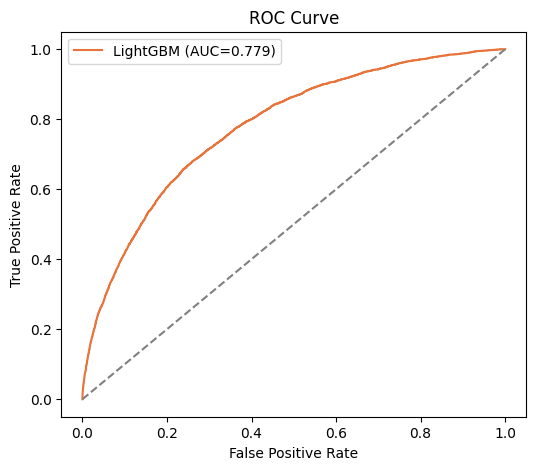

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [36]:
from sklearn.metrics import roc_curve, roc_auc_score
import matplotlib.pyplot as plt
from google.colab import files

auc = roc_auc_score(y_test, pred)
fpr, tpr, _ = roc_curve(y_test, pred)
print("AUC :", round(auc, 4))
print("Gini:", round(2*auc - 1, 4))
print("KS  :", round((tpr - fpr).max(), 4))

plt.figure(figsize=(6,5))
plt.plot(fpr, tpr, color='#E8743B', label=f'LightGBM (AUC={auc:.3f})')
plt.plot([0,1], [0,1], '--', color='grey')
plt.xlabel("False Positive Rate"); plt.ylabel("True Positive Rate")
plt.title("ROC Curve"); plt.legend()
plt.savefig("roc_curve.png", dpi=150, bbox_inches='tight')
plt.show()
files.download("roc_curve.png")

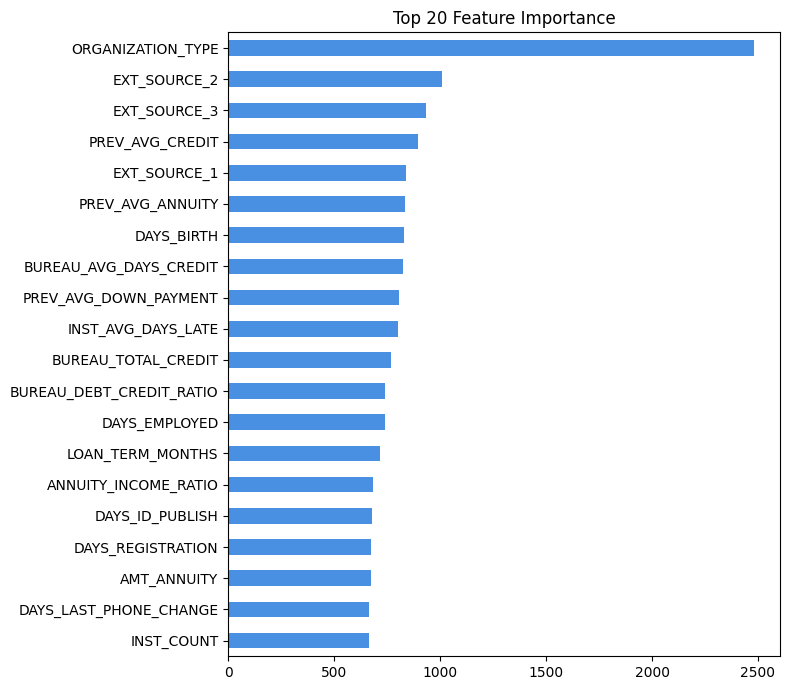

/usr/local/lib/python3.13/dist-packages/shap/explainers/_tree.py:578: UserWarning: LightGBM binary classifier with TreeExplainer shap values output has changed to a list of ndarray
  warnings.warn(


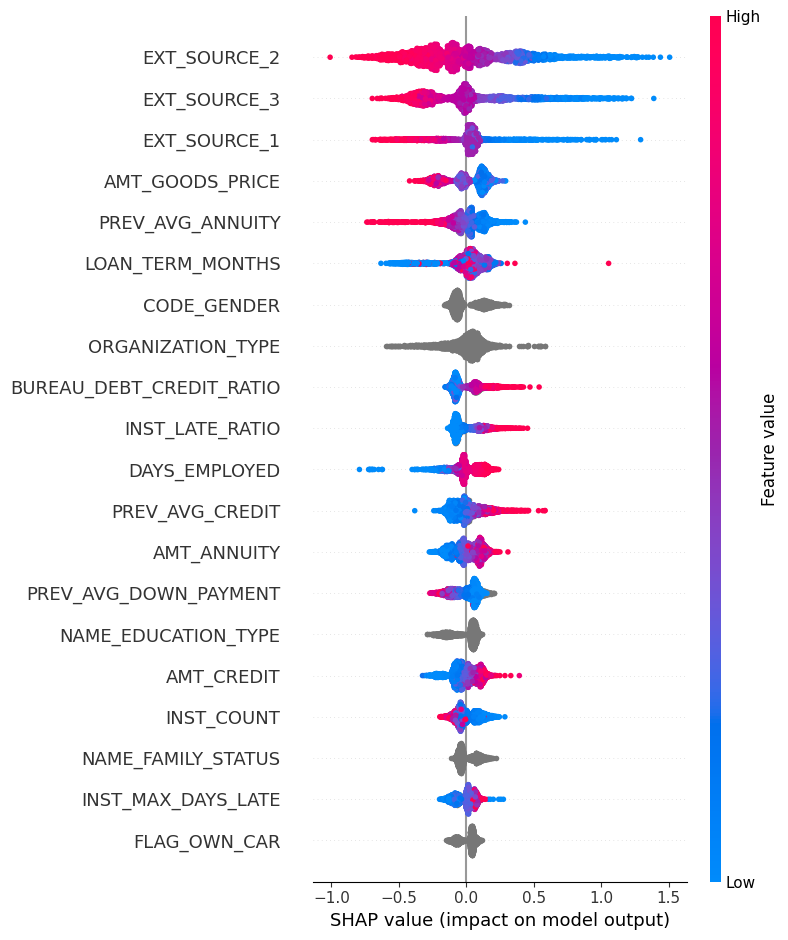

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [37]:
import pandas as pd
import matplotlib.pyplot as plt
import shap
from google.colab import files

# 1) Feature importance
imp = pd.Series(model.feature_importances_, index=X.columns).sort_values().tail(20)
plt.figure(figsize=(8,7))
imp.plot(kind='barh', color='#4A90E2')
plt.title("Top 20 Feature Importance")
plt.tight_layout()
plt.savefig("feature_importance.png", dpi=150, bbox_inches='tight')
plt.show()

# 2) SHAP summary
sample = X_test.sample(3000, random_state=42)
explainer = shap.TreeExplainer(model)
sv = explainer.shap_values(sample)
sv = sv[1] if isinstance(sv, list) else sv
shap.summary_plot(sv, sample, show=False)
plt.savefig("shap_summary.png", dpi=150, bbox_inches='tight')
plt.show()

# Download
files.download("feature_importance.png")
files.download("shap_summary.png")